In [1]:
import os
import csv
import argparse
from multiprocessing import Pool, cpu_count

import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import custom_object_scope
from tensorflow import keras
from tensorflow.keras.optimizers.schedules import LearningRateSchedule

# Loading In Model
from models.model_utils import CosineDecay, ScalarAttention, CrossModalAttention, TemporalAttention 
from models.models import get_model_instance

# Packages for Base-Pair Kernel Visualization
import matplotlib.pyplot as plt
import numpy as np

# Packages for Motif Plots for Base-Pair Kernels
import matplotlib as mpl
from matplotlib.text import TextPath
from matplotlib.patches import PathPatch
from matplotlib.font_manager import FontProperties
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Packages for SHAP
import shap
import pickle
from preprocessing.generate_tf_splits import *
from preprocessing.compile_sample_data import *

#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/model.h5"
#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/best_model.h5"
#best_model = tf.keras.models.load_model(model_path, custom_objects={'CosineDecay': CosineDecay, 'ScalarAttention': ScalarAttention, 'CrossModalAttention': CrossModalAttention, 'TemporalAttention': TemporalAttention})
# print(best_model.summary())

#Instantiate a new empty model
#model_path = "/fh/fast/ha_g/user/anetzley/final_models/01-30-24_final_weights.hdf5"
model_path = "/fh/fast/ha_g/user/anetzley/final_models/penultimate_weights.hdf5"
hypermodel = get_model_instance("BioCNN")
best_model = hypermodel.build_default()
best_model.load_weights(model_path)
best_model.summary()

#save model as an h5 file to a specified location
#best_model.save("/fh/fast/ha_g/user/anetzley/model/02-05-24_pen_model.h5")

#best_model = model


Base-Pair Kernel Visualization

In [117]:
## Visualizing 1 kernel from the depthwise 2d layer
actg_conv_layer = best_model.get_layer(name='conv2d')
weights = actg_conv_layer.get_weights()[0]
print(weights.shape)
fig, axs = plt.subplots(4, 4, figsize=(15, 7))
for j in range(4):
  for i in range(4):
    axs[j, i].imshow(weights[:, :, 0, 4*j + i], cmap='viridis')
    axs[j, i].set_yticks(np.arange(4))
    axs[j, i].set_yticklabels(['A', 'C', 'G', 'T'])
cbar = fig.colorbar(axs[0, 0].imshow(weights[:, :, 0, 0], cmap='viridis'), ax=axs, orientation='vertical', fraction=0.05)
# Add in a label on the y axis of each plot

cbar.set_label('Weight')
fig.suptitle(f'Base-Pair Conv Filters', fontsize=16)
plt.show()
plt.savefig(f"/fh/fast/ha_g/user/anetzley/plots/conv2_filters/00.png")

ValueError: No such layer: conv2d. Existing layers are: ['TSS_image', 'tf.__operators__.getitem_16', 'tf.compat.v1.transpose_1', 'tf.expand_dims_1', 'tf.__operators__.getitem_9', 'tf.__operators__.getitem_10', 'tf.__operators__.getitem_11', 'tf.__operators__.getitem_12', 'tf.__operators__.getitem_13', 'tf.__operators__.getitem_14', 'tf.__operators__.getitem_15', 'conv2d_1', 'conv1d_11', 'conv1d_12', 'conv1d_13', 'conv1d_14', 'conv1d_15', 'conv1d_16', 'conv1d_17', 'tf.compat.v1.squeeze_2', 'tf.stack_1', 'batch_normalization_15', 'tf.__operators__.getitem_17', 'conv3d_1', 'tf.compat.v1.squeeze_3', 'batch_normalization_16', 'average_pooling1d_4', 'conv1d_18', 'batch_normalization_17', 'average_pooling1d_5', 'conv1d_19', 'batch_normalization_18', 'average_pooling1d_6', 'conv1d_20', 'batch_normalization_19', 'average_pooling1d_7', 'conv1d_21', 'batch_normalization_20', 'flatten_1', 'dense_9', 'batch_normalization_21', 'dropout_9', 'dense_10', 'batch_normalization_22', 'dropout_10', 'dense_1

Motif-Plots for Base-Pair Kernels

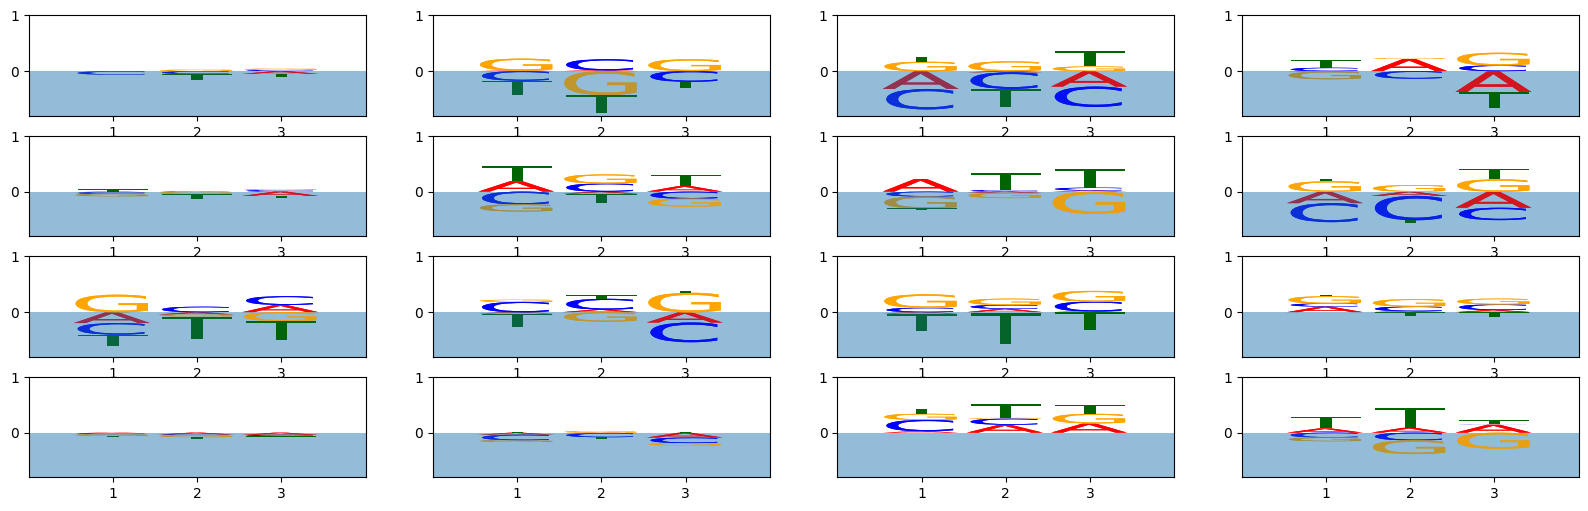

In [6]:
#Data Processing

def shift(x): # column shift
    x = x - np.min(x, axis=0)  # Subtracting the min value from each column to make each column non-negative
    return x / x.sum(axis=0)


max_weight = np.max(weights)
min_weight = np.min(weights)
diff  = max_weight - min_weight

def global_shift(x, diff = diff): 
    return x / diff # global shift # Divide each value by the max - min of all filter values across all filters

processed_motif_data = {}
for filter_number in range(weights.shape[3]):
    #print(filter_number)
    processed_filter = global_shift(weights[:, :, 0, filter_number])

    processed_motif_data_list = []
    for position in range(weights.shape[1]):
        processed_motif_data_list.append([
            ('A', processed_filter[0, position]),
            ('C', processed_filter[1, position]),
            ('G', processed_filter[2, position]),
            ('T', processed_filter[3, position])
        ])
    processed_motif_data[filter_number] = processed_motif_data_list


# Define Letter-Drawing Patch Code
globscale = 1.35
LETTERS = { "T" : TextPath((-0.305, 0), "T", size=1),
            "G" : TextPath((-0.384, 0), "G", size=1),
            "A" : TextPath((-0.35, 0), "A", size=1),
            "C" : TextPath((-0.366, 0), "C", size=1) }
COLOR_SCHEME = {'G': 'orange', 
                'A': 'red', 
                'C': 'blue', 
                'T': 'darkgreen'}

def letterAt(letter, x, y, yscale=1, ax=None, neg=False):
    text = LETTERS[letter]
    if neg and yscale <= 0: # If the yscale is negative, flip the letter ONLY when neg is True
        t = mpl.transforms.Affine2D().scale(1*globscale, -yscale*globscale) + \
            mpl.transforms.Affine2D().translate(x, y) + ax.transData
    else:
        t = mpl.transforms.Affine2D().scale(1*globscale, yscale*globscale) + \
            mpl.transforms.Affine2D().translate(x,y) + ax.transData
            
    p = PathPatch(text, lw=0, fc=COLOR_SCHEME[letter],  transform=t)
    if ax != None:
        ax.add_artist(p)
    return p

# Plotting the motif filters
fig, axs = plt.subplots(4, 4, figsize=(20,6))

all_scores = processed_motif_data_list

#All values shifted postive, scaled to [0,1]
for j in range(4):
  for i in range(4):
    #Extract a specfic filter
    all_scores = processed_motif_data[j*4 + i]
    x = 1
    maxi = 0
    for scores in all_scores:
        y_down_score = 0
        y_up_score = 0
        for base, score in scores:
            if score > 0:
                letter = letterAt(base, x, y_up_score, score, axs[j, i], True)
                y_up_score += score
            else:
                y_down_score += score
                letter = letterAt(base, x, y_down_score, score, axs[j, i], True)

            axs[j, i].add_patch(letter)
            axs[j, i].add_patch(patches.Rectangle((0, -1), 4,1,alpha = 0.05)) #transparency
        x += 1

    axs[j, i].set_xticks(range(1, x))
    axs[j, i].set_xlim((0, x))
    axs[j, i].set_ylim((-0.8, 1))  

plt.show()

Signal Kernel Visualization

In [38]:
## Visualizing all 7 signal first layer 3x1 kernels
triton_signals = ['depth', 'nucleosome cp', 'phased-nucleosome cp', 'fl short/long ratio', 'fl diversity', 'fl entropy', 'peak locations']

for signal_num in range(len(triton_signals)):
    continue
    #Extract the weights of the corresponding first convolutional layer
    if signal_num == 0:
        first_conv_layer = best_model.get_layer(name='conv1d')
    else:
        first_conv_layer = best_model.get_layer(name=f'conv1d_{signal_num}')
    weights = first_conv_layer.get_weights()[0]
    print(weights.shape)

    fig, axs = plt.subplots(6, 8, figsize=(15, 7))

    for i in range(6):
        for j in range(8):
            axs[i, j].imshow(weights[:, :, 8*i + j], cmap='viridis')
            axs[i, j].axis('off')

    # Add color bar
    cbar = fig.colorbar(axs[0, 0].imshow(weights[:, :, 0], cmap='viridis'), ax=axs, orientation='vertical', fraction=0.05)
    cbar.set_label('Weight')

    # Add title
    signal_name = triton_signals[signal_num]
    fig.suptitle(f'Convolutional Layer 1 Filters for {signal_name}', fontsize=16)
    fig.show()
    fig.savefig(f"/fh/fast/ha_g/user/anetzley/plots/conv1_filters/{signal_name}.png")

Conv3D Signal Combination Filter Visualization

(1, 8, 64, 1, 128)


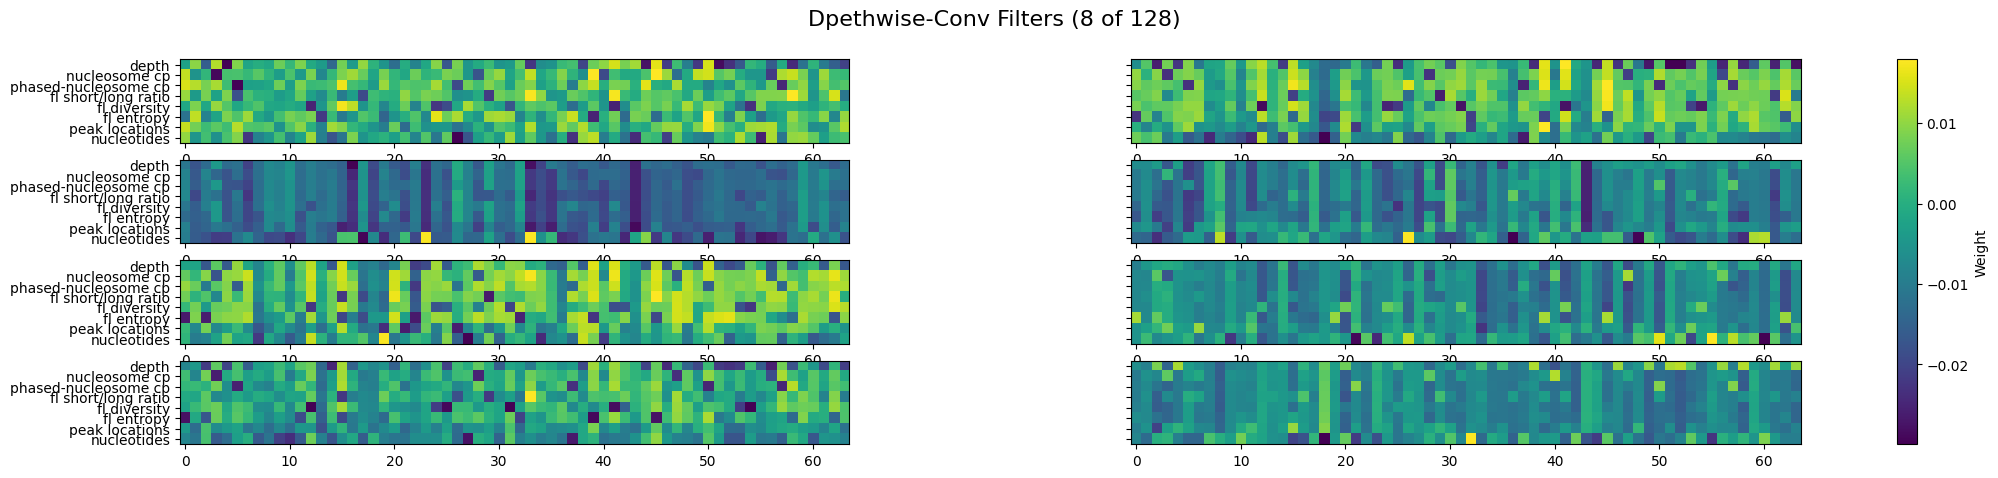

<Figure size 640x480 with 0 Axes>

In [37]:
## Visualizing 1 kernel from the depthwise 2d layer
conv_layer = best_model.get_layer(name='conv3d')
weights = conv_layer.get_weights()[0]
print(weights.shape)
fig, axs = plt.subplots(4, 2, figsize=(25,5))
for j in range(4):
  for i in range(2):
    axs[j, i].imshow(np.squeeze(weights[:, :, :, :, 4*j + i]), cmap='viridis')
    axs[j, i].set_yticks(np.arange(8))
    if i == 0:
      axs[j, i].set_yticklabels(['depth', 'nucleosome cp', 'phased-nucleosome cp', 'fl short/long ratio', 'fl diversity', 'fl entropy', 'peak locations', 'nucleotides'])
    else:
      axs[j, i].set_yticklabels([])
cbar = fig.colorbar(axs[0, 0].imshow(np.squeeze(weights[:, :, :, :, 0]), cmap='viridis'), ax=axs, orientation='vertical', fraction=0.05)
# Add in a label on the y axis of each plot
#plt.subplots_adjust(hspace=0.5)
cbar.set_label('Weight')
fig.suptitle(f'Dpethwise-Conv Filters ({(j+1)*(i+1)} of 128)', fontsize=16)
plt.show()
plt.savefig(f"/fh/fast/ha_g/user/anetzley/plots/conv2_filters/00.png")

Note, here it looks like a few of these filters are focusing primarily on nucleotides, whie others focus on signal 

Data Loading

In [98]:
#Data Loading helper Functions

def tf_ds_np_array(ds, num_elements=None):
    if num_elements is not None:
        ds = ds.take(num_elements)
    for element in ds:
        TSS_image_list.append(element['TSS_image'].numpy())
        TSS_scalar_list.append(element['TSS_scalars'].numpy())
        GB_scalar_list.append(element['GB_scalars'].numpy())
        ref_scalar_list.append(element['ref_scalars'].numpy())

        TSS_image_stack = np.stack(TSS_image_list)
        TSS_scalar_stack = np.stack(TSS_scalar_list)
        GB_scalar_stack = np.stack(GB_scalar_list)
        ref_scalar_stack = np.stack(ref_scalar_list)

    input_data = [TSS_image_stack, TSS_scalar_stack, GB_scalar_stack, ref_scalar_stack]
    return input_data


def normalize(x):
    return (x - np.mean(x, axis = 0)[np.newaxis]) / np.std(x, axis = 0)[np.newaxis]


def subsample(input_data, sample_size = 20):
    np.random.seed(200)
    sample_indices = np.random.choice(input_data[0].shape[0], sample_size, replace=False)
    input_data_sample = [input_data[0][sample_indices], input_data[1][sample_indices], input_data[2][sample_indices], input_data[3][sample_indices]]

    return input_data_sample

def save_npz(input_data, filepath):
    TSS_image_stack = input_lucap_up[0]
    TSS_scalar_stack = input_lucap_up[1]
    GB_scalar_stack = input_lucap_up[2]
    ref_scalar_stack = input_lucap_up[3]
    np.savez(filepath, TSS_image_stack = TSS_image_stack, TSS_scalar_stack = TSS_scalar_stack, GB_scalar_stack = GB_scalar_stack, ref_scalar_stack = ref_scalar_stack)

def load_npz(filepath):
    #Load input_data from my local folder
    input_data_npz = np.load(filepath, allow_pickle=True)

    #unpack the input_data, store it in a list
    input_data = []
    for key in input_data_npz:
        input_data.append(input_data_npz[key])
    return input_data

def get_gene_subset(input_data, gene_list_path):
    #gene_list_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/RNA-Seq/LuCaPvsGTEx_up-regulated.txt"
    gene_list = pd.read_table(gene_list_path, header=None, names=['gene_name'])

    #convert dataframe to list
    gene_list = gene_list['gene_name'].tolist()
    ds_subset = ds.filter(lambda x: tf.reduce_any(tf.equal(x['gene_name'], gene_list)))
    return ds_subset


    

In [3]:
#Load my trainset data for SHAP Analysis

ds_raw = tf.data.TFRecordDataset('/fh/fast/ha_g/user/anetzley/data_for_shap/full_dataset/AllSamples_0x_0TPM.tfrecord')
#ds_raw = tf.data.TFRecordDataset('/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/data/validation_10.0x/LuCaP_136.tfrecord')
ds = ds_raw.cache()
ds = ds.shuffle(1024*8)
opt = tf.data.Options()
opt.experimental_deterministic = False
ds = ds.with_options(opt)
# Parse the data
ds = ds.map(lambda x: parse_serialized_example(x, labeled=True))

norm = False

#Extract data as numpy array and store in SHAP-friendly manner
input_data = tf_ds_np_array(ds, 1000)

Instructions for updating:
Lambda fuctions will be no more assumed to be used in the statement where they are used, or at least in the same block. https://github.com/tensorflow/tensorflow/issues/56089


2024-02-21 09:10:53.519331: W tensorflow/core/kernels/data/cache_dataset_ops.cc:856] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [7]:
# Save the input data to an npz file for easy access

import numpy as np
#Save input_data as an npz to my local folder
#np.savez('/fh/fast/ha_g/user/anetzley/data_for_shap/full_dataset/input_data.npz', TSS_image_stack = TSS_image_stack, TSS_scalar_stack = TSS_scalar_stack, GB_scalar_stack = GB_scalar_stack, ref_scalar_stack = ref_scalar_stack)

##Load input_data from my local folder
#input_data = np.load('/fh/fast/ha_g/user/anetzley/data_for_shap/input_data.npz', allow_pickle=True)

#unpack the input_data, store it in a list
input_data_full = []
for key in input_data:
    input_data_full.append(input_data[key])
    

In [42]:
#Randomly subsample the full dataset


input_data_full = input_data

input_data_background = subsample(input_data_full, sample_size = 1000)
input_data_test = subsample(input_data_full, sample_size = 100)
input_data_single = subsample(input_data_full, sample_size = 1)



In [ ]:
#Plotting the first signal
import matplotlib.pyplot as plt
plt.clf()
cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks', '8. A-Adenine', '9. C-Cytosine', '10. G-Guanine', '11. T-Tyrosine']

fig, axs = plt.subplots(len(cols), 1, figsize=(8, 11))
for i in range(len(cols)):
    axs[i].plot(input_data_background[0][0][:, i])
    axs[i].set_ylabel(cols[i], rotation=0)

plt.show()


Gene Subsetting

In [55]:
gene_list_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/RNA-Seq/LuCaPvsGTEx_down-regulated.txt"

#Extract genes from the dataset that match the genes in the gene list
lucap_down_ds = get_gene_subset(ds, gene_list_path)

#Convert the dataset to a numpy array
input_lucap_down = tf_ds_np_array(lucap_down_ds)



In [99]:
# Save the input data to an npz file for easy access

filepath = '/fh/fast/ha_g/user/anetzley/data_for_shap/Lucap_vs_GTX_up/input_data.npz'
#save_npz(input_lucap_down, filepath)

input_lucap_up = load_npz(filepath)

In [100]:
input_data_full = input_lucap_up

input_data_background = subsample(input_data_full, sample_size = 1000)
input_data_test = subsample(input_data_full, sample_size = 100)
input_data_single = subsample(input_data_full, sample_size = 1)

In [105]:
input_data_background_up = subsample(input_lucap_up, sample_size = 1000)
input_data_test_up = subsample(input_lucap_up, sample_size = 100)
input_data_single_up = subsample(input_lucap_up, sample_size = 1)
input_data_background_down = subsample(input_lucap_down, sample_size = 1000)
input_data_test_down = subsample(input_lucap_down, sample_size = 100)
input_data_single_down = subsample(input_lucap_down, sample_size = 1)

In [47]:


#extract the first entry of the input data test
input_data_new = [input_data_test[0][0][np.newaxis], input_data_test[1][0][np.newaxis], input_data_test[2][0][np.newaxis], input_data_test[3][0][np.newaxis]]

input_data_new[0].shape

(1, 2000, 11)

In [106]:
#Loop through all 100 samples and extract a single each time, and then predict the output
pred_list_up = []
for i in range(100):
    input_data_temp = [input_data_test_up[0][i][np.newaxis], input_data_test_up[1][i][np.newaxis], input_data_test_up[2][i][np.newaxis], input_data_test_up[3][i][np.newaxis]]
    pred = best_model.predict(input_data_temp)
    pred_list_up.append(pred[0, 0])

print(np.sum(np.array(pred_list) > 5))

pred_list_down = []
for i in range(100):
    input_data_temp = [input_data_test_down[0][i][np.newaxis], input_data_test_down[1][i][np.newaxis], input_data_test_down[2][i][np.newaxis], input_data_test_down[3][i][np.newaxis]]
    pred = best_model.predict(input_data_temp)
    pred_list_down.append(pred[0, 0])

print(np.sum(np.array(pred_list) > 5))

#Expressed in 79 of 100 samples in Up
#Expressed in 63 of 100 samples in Down

1/1 [==============================] - 0s 39ms/step
43
1/1 [==============================] - 0s 40ms/step
43


Text(0.5, 0, 'Predicted Expression Level')

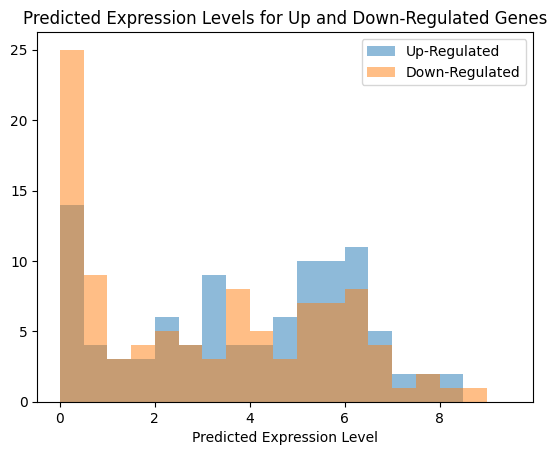

In [115]:
plt.hist(pred_list_up, bins = np.arange(0, 10, 0.5), alpha = 0.5)
#plt.title('Predicted Expression Levels for Up-Regulated Genes')
plt.hist(pred_list_down, bins = np.arange(0, 10, 0.5), alpha = 0.5)
plt.title('Predicted Expression Levels for Up and Down-Regulated Genes')
plt.legend(['Up-Regulated', 'Down-Regulated'])
plt.xlabel('Predicted Expression Level')


SHAP Analysis

In [59]:
## Execute the SHAP Analysis
path  = "/fh/fast/ha_g/user/anetzley/interpretation"

#input_data = input_data_sample

#shap_values, shap_value_vars = run_shap(best_model, input_data, path)
explainer = shap.GradientExplainer(best_model, input_data_background)
shap_values, shap_value_vars = explainer.shap_values(input_data_test, return_variances = True)

`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


<Figure size 640x480 with 0 Axes>

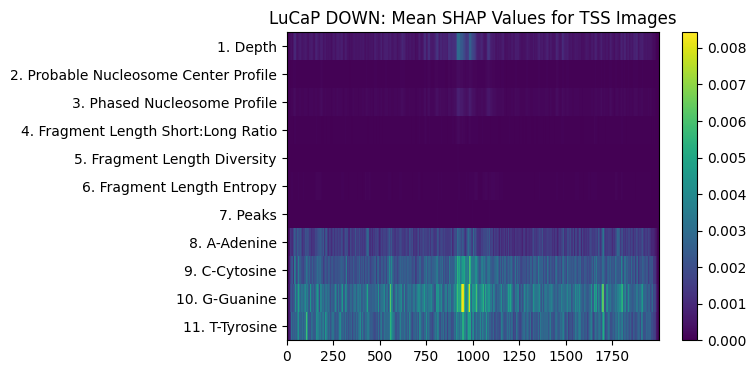

In [62]:
# Plot mean abs SHAP Values for the TSS Images

images = np.array(shap_values[0][0])
images_t = np.transpose(images, (2,0,1))
means = np.mean(np.abs(images_t), axis=1)
plt.clf()
cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long Ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks', '8. A-Adenine', '9. C-Cytosine', '10. G-Guanine', '11. T-Tyrosine']
plt.figure(figsize=(6, 4))
plt.imshow(means, cmap='viridis', aspect='auto', interpolation='nearest')

# Add colorbar for reference
plt.title('LuCaP DOWN: Mean SHAP Values for TSS Images')
plt.colorbar()
plt.yticks(np.arange(len(cols)), cols)
# Show the plot
plt.show()


In [23]:
np.sum(np.mean(images_t, axis = 1), axis = 1)

array([-0.02423374,  0.00046936, -0.00206148,  0.00135571, -0.00024998,
        0.00110228,  0.00022883, -0.00657088, -0.01991747, -0.03471351,
       -0.05427045])

Nucleotides all as one feature

(100, 2000)
(8, 100, 2000)


<Figure size 640x480 with 0 Axes>

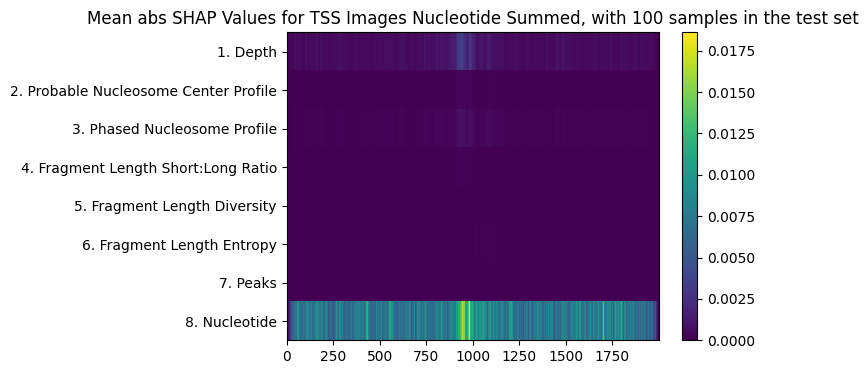

In [24]:
images_t.shape
new_images_t = images_t.copy()
summed_bp_shap = np.sum(new_images_t[7:11], axis=0)
print(summed_bp_shap.shape)
new_images_t[7] = summed_bp_shap
new_images_t = new_images_t[:8]
new_means = np.mean(np.abs(new_images_t), axis=1)
print(new_images_t.shape)

plt.clf()
new_cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long Ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks', '8. Nucleotide']
plt.figure(figsize=(6, 4))
plt.imshow(new_means, cmap='viridis', aspect='auto', interpolation='nearest')

# Add colorbar for reference
plt.title(f'Mean abs SHAP Values for TSS Images Nucleotide Summed, with {new_images_t.shape[1]} samples in the test set')
plt.colorbar()
plt.yticks(np.arange(len(new_cols)), new_cols)
# Show the plot
plt.show()

Extracting Signals Individually

<Figure size 640x480 with 0 Axes>

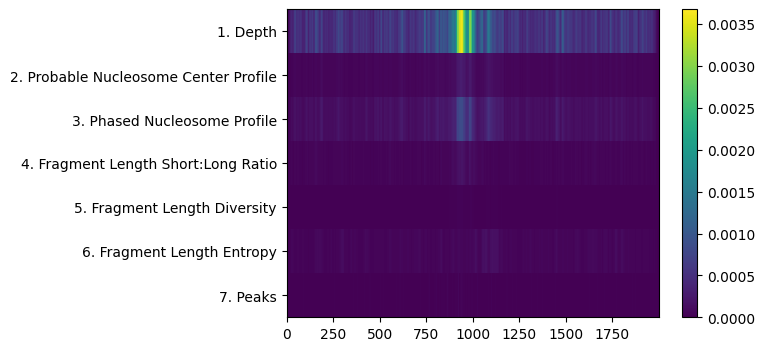

In [25]:
plt.clf()
new_cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long Ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks']
plt.figure(figsize=(6, 4))
plt.imshow(new_means[:7, :], cmap='viridis', aspect='auto', interpolation='nearest')

# Add colorbar for reference
plt.colorbar()
plt.yticks(np.arange(len(new_cols)), new_cols)
# Show the plot
plt.show()

Text(0.5, 0.98, 'LuCaP DOWN: Mean SHAP Values for TSS Images Nucleotide Summed, with 100 samples in the test set')

<Figure size 640x480 with 0 Axes>

<Figure size 600x400 with 0 Axes>

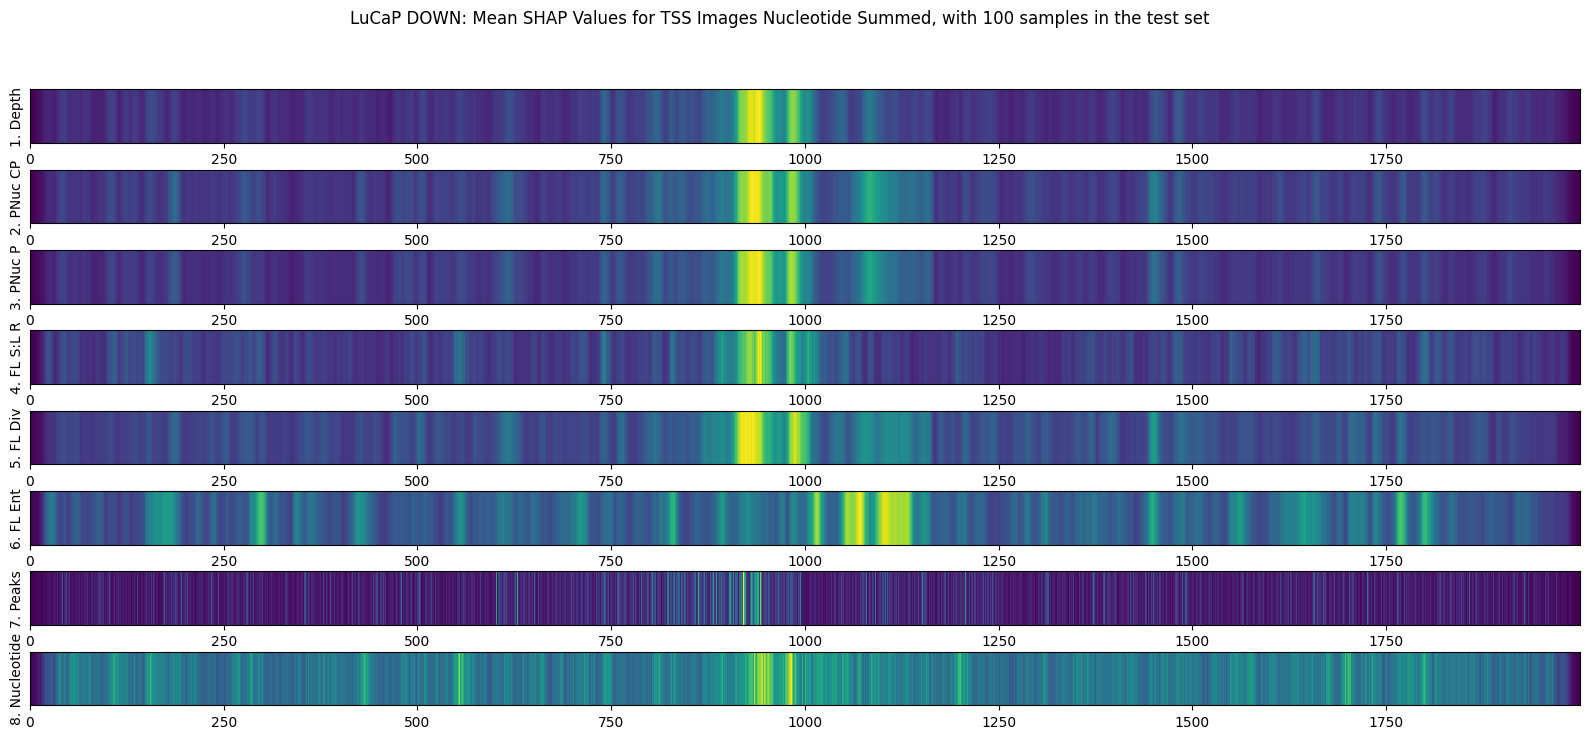

In [63]:

plt.clf()
new_cols = ['1. Depth', '2. PNuc CP', '3. PNuc P', '4. FL S:L R', '5. FL Div', '6. FL Ent', '7. Peaks', '8. Nucleotide']
plt.figure(figsize=(6, 4))
fig, axs = plt.subplots(8, 1, figsize=(20,8))
for j in range(8):
  axs[j].imshow(new_means[j, :][np.newaxis], cmap='viridis', aspect='auto', interpolation='nearest')
  axs[j].set_yticks([])
  axs[j].set_ylabel(new_cols[j])

plt.subplots_adjust(hspace=0.5)
plt.suptitle(f'LuCaP DOWN: Mean SHAP Values for TSS Images Nucleotide Summed, with {new_images_t.shape[1]} samples in the test set')
#cbar = fig.colorbar(axs[0, 0].imshow(np.squeeze(weights[:, :, :, :, 0]), cmap='viridis'), ax=axs, orientation='vertical', fraction=0.05)

Summing Across 2000 dim to obtain overall SHAP for each signal

In [227]:
np.mean(np.abs(np.sum(new_images_t, axis = 2)), axis = 1)

array([0.31524566, 0.02518408, 0.0844292 , 0.0116965 , 0.00284759,
       0.01634892, 0.00144178, 0.97562183])

In [221]:
np.sum(np.mean(np.abs(new_images_t), axis = 1), axis = 1)

array([ 1.2707658 ,  0.12934087,  0.34510921,  0.08404052,  0.01720699,
        0.11986066,  0.01508443, 12.66895215])

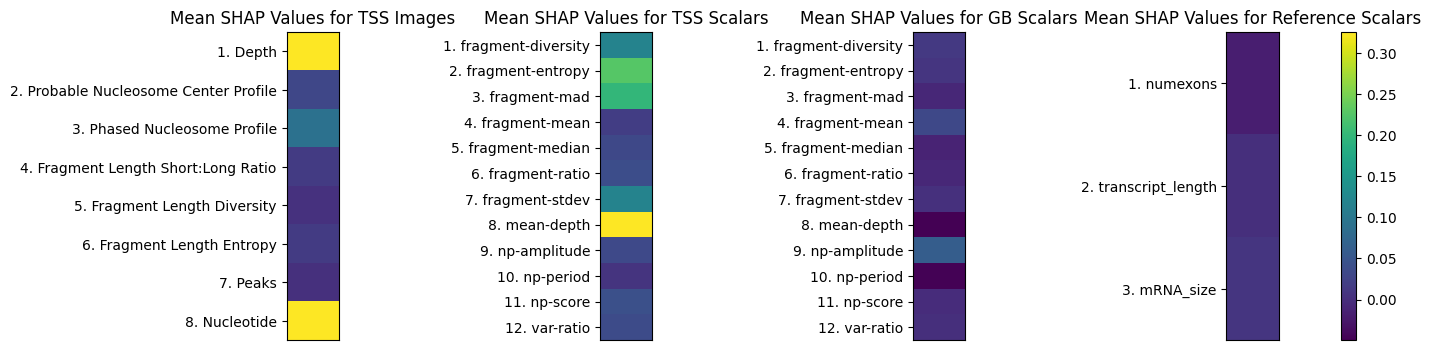

In [64]:
# Plot mean abs SHAP Values for the TSS Scalars, GB Scalars, and Reference Scalars, and summed signals

TSS_image_cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long Ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks', '8. Nucleotide']
TSS_scalar_cols = ['1. fragment-diversity', '2. fragment-entropy', '3. fragment-mad', '4. fragment-mean', '5. fragment-median', '6. fragment-ratio', '7. fragment-stdev', '8. mean-depth', '9. np-amplitude', '10. np-period', '11. np-score', '12. var-ratio' ]
ref_scalar_cols = ['1. numexons', '2. transcript_length', '3. mRNA_size']
cols_list = [TSS_image_cols, TSS_scalar_cols, TSS_scalar_cols, ref_scalar_cols]
name_list = ['TSS Images', 'TSS Scalars', 'GB Scalars', 'Reference Scalars']
fig, axs = plt.subplots(1,4, figsize=(16, 4))

TSS_images_summed = np.mean(np.abs(np.sum(new_images_t, axis = 2)), axis = 1)[:, np.newaxis]

TSS_scalars = np.mean(np.abs(shap_values[0][1]), axis = 0)[:, np.newaxis]
TSS_scalars_std = np.std(shap_values[0][1], axis = 0)[:, np.newaxis]

GB_scalars = np.mean(shap_values[0][2], axis = 0)[:, np.newaxis]
GB_scalars_std = np.std(shap_values[0][2], axis = 0)[:, np.newaxis]

ref_scalars = np.mean(shap_values[0][3], axis = 0)[:, np.newaxis]
ref_scalars_std = np.std(shap_values[0][3], axis = 0)[:, np.newaxis]

shap_values_summed = [TSS_images_summed, TSS_scalars, GB_scalars, ref_scalars]

vmin = min(np.min(TSS_images_summed), np.min(TSS_scalars), np.min(GB_scalars), np.min(ref_scalars))
vmax = max(np.max(TSS_scalars), np.max(GB_scalars), np.max(ref_scalars))

for i in range(4):
    if i == 0:
        im = axs[i].imshow(shap_values_summed[i][np.newaxis], cmap='viridis', aspect='auto', interpolation='nearest', vmax=vmax, vmin=vmin)
    axs[i].imshow(shap_values_summed[i], cmap='viridis', aspect='auto', interpolation='nearest', vmax=vmax, vmin=vmin)
    axs[i].set_yticks(np.arange(len(cols_list[i])), cols_list[i])
    axs[i].set_xticks([])
    axs[i].set_title(f'Mean SHAP Values for {name_list[i]}')

fig.subplots_adjust(wspace=5) 
fig.colorbar(im, ax=axs.ravel().tolist())
fig.show()

In [ ]:
# Plot mean abs SHAP Values for the TSS Scalars, GB Scalars, and Reference Scalars

TSS_scalar_cols = ['1. fragment-diversity', '2. fragment-entropy', '3. fragment-mad', '4. fragment-mean', '5. fragment-median', '6. fragment-ratio', '7. fragment-stdev', '8. mean-depth', '9. np-amplitude', '10. np-period', '11. np-score', '12. var-ratio' ]
ref_scalar_cols = ['1. numexons', '2. transcript_length', '3. mRNA_size']

fig, axs = plt.subplots(1,3, figsize=(12, 4))

TSS_scalars = np.mean(np.abs(shap_values[0][1]), axis = 0)[:, np.newaxis]
TSS_scalars_std = np.std(shap_values[0][1], axis = 0)[:, np.newaxis]

GB_scalars = np.mean(shap_values[0][2], axis = 0)[:, np.newaxis]
GB_scalars_std = np.std(shap_values[0][2], axis = 0)[:, np.newaxis]

ref_scalars = np.mean(shap_values[0][3], axis = 0)[:, np.newaxis]
ref_scalars_std = np.std(shap_values[0][3], axis = 0)[:, np.newaxis]

vmin = min(np.min(TSS_scalars), np.min(GB_scalars), np.min(ref_scalars))
vmax = max(np.max(TSS_scalars), np.max(GB_scalars), np.max(ref_scalars))

axs[0].imshow(TSS_scalars, cmap='viridis', aspect='auto', interpolation='nearest', vmax=vmax, vmin=vmin)
axs[0].set_yticks(np.arange(len(TSS_scalar_cols)), TSS_scalar_cols)
axs[0].set_xticks([])
axs[0].set_title('Mean Shap Values for TSS Scalars')

axs[1].imshow(GB_scalars, cmap='viridis', aspect='auto', interpolation='nearest', vmax=vmax, vmin=vmin)
axs[1].set_yticks(np.arange(len(TSS_scalar_cols)), TSS_scalar_cols)
axs[1].set_xticks([])
axs[1].set_title('Mean Shap Values for GB Scalars')

im3 = axs[2].imshow(ref_scalars, cmap='viridis', aspect='auto', interpolation='nearest', vmax=vmax, vmin=vmin)
axs[2].set_yticks(np.arange(len(ref_scalar_cols)), ref_scalar_cols)
axs[2].set_xticks([])
axs[2].set_title('Mean Shap Values for reference Scalars')

#cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.subplots_adjust(wspace=5) 
fig.colorbar(im3, ax=axs.ravel().tolist())
fig.show()

<Figure size 640x480 with 0 Axes>

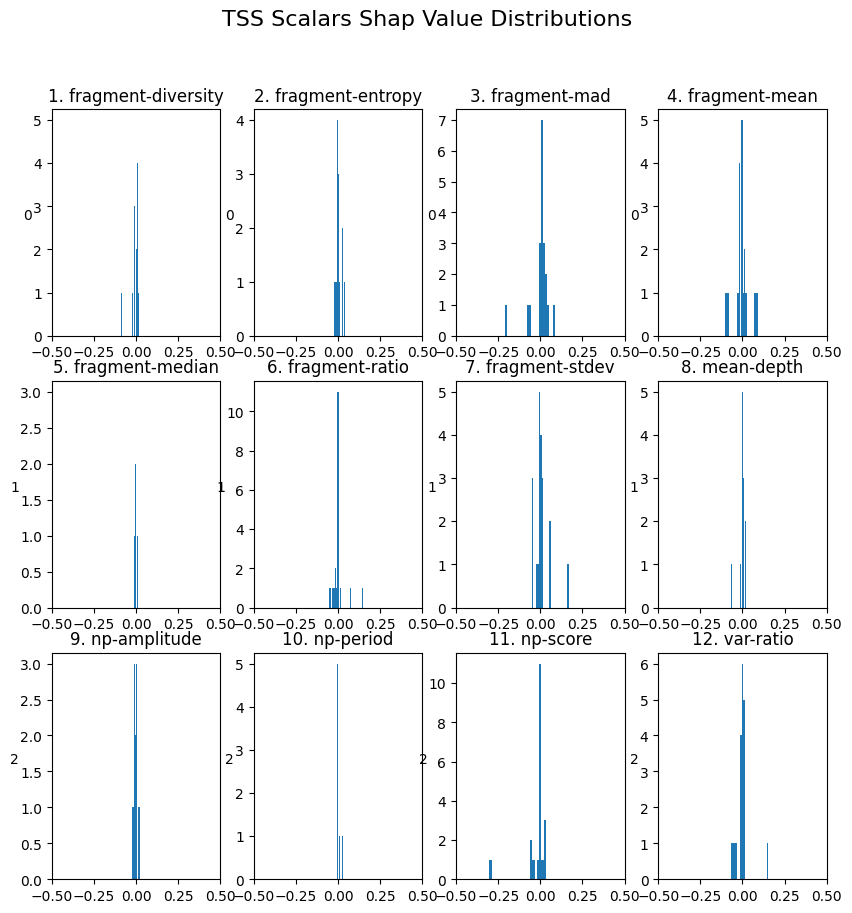

<Figure size 640x480 with 0 Axes>

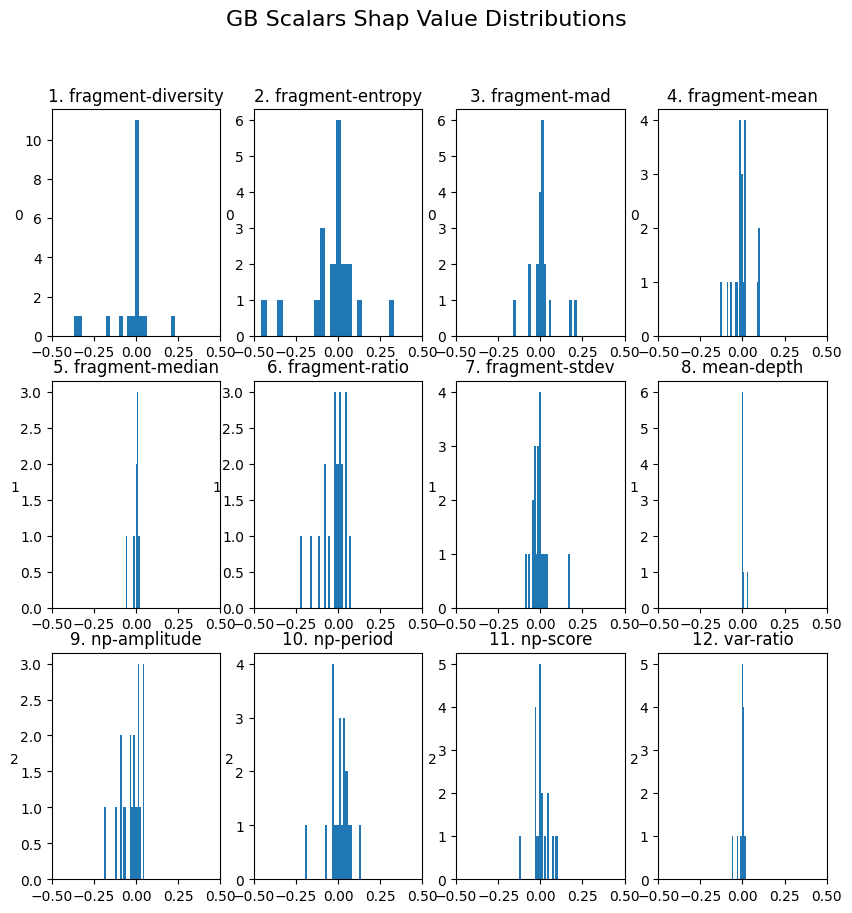

In [21]:
#plot the distribution of shap values for each scalar
plt.clf()
fig, axs = plt.subplots(3, 4, figsize=(10, 10))
for i in range(3):
    for j in range(4):
        axs[i, j].hist(shap_values[0][1][:, 4*i + j], bins=25)
        axs[i, j].set_ylabel(f'{i}', rotation=0)
        axs[i, j].set_title(TSS_scalar_cols[4*i + j])
        axs[i, j].set_xlim(-0.5, 0.5)

fig.suptitle('TSS Scalars Shap Value Distributions', fontsize=16)
plt.show()

plt.clf()
fig, axs = plt.subplots(3, 4, figsize=(10, 10))
for i in range(3):
    for j in range(4):
        axs[i, j].hist(shap_values[0][2][:, 4*i + j], bins=25)
        axs[i, j].set_ylabel(f'{i}', rotation=0)
        axs[i, j].set_title(TSS_scalar_cols[4*i + j])
        axs[i, j].set_xlim(-0.5, 0.5)

fig.suptitle('GB Scalars Shap Value Distributions', fontsize=16)
plt.show()

In [11]:
#Randomly subsample the full dataset
def subsample(input_data, sample_size = 20):
    np.random.seed(0)
    sample_indices = np.random.choice(input_data[0].shape[0], sample_size, replace=False)
    input_data_sample = [input_data[0][sample_indices], input_data[1][sample_indices], input_data[2][sample_indices], input_data[3][sample_indices]]

    return input_data_sample

np.random.seed(0)
input_data_full = input_data

input_data_sample = subsample(input_data_full, sample_size = 20)
input_data_one = subsample(input_data_full, sample_size = 1)

print(input_data_one[0][:, :4, :4])
print(np.mean(input_data_sample[0][:, :4, :4], axis = 0))


[[[1.3400773 1.8089526 1.7459344 1.2532669]
  [1.362363  1.8491669 1.7476028 1.1697158]
  [1.3852881 1.848495  1.7488331 1.1997086]
  [1.3852881 1.8470047 1.7496243 1.1997086]]]
[[1.0042272 1.0696701 1.073756  1.0279709]
 [1.0082347 1.0712525 1.074748  1.0344315]
 [1.0218456 1.0855403 1.0757604 1.038006 ]
 [1.0254861 1.0855314 1.076792  1.053626 ]]


In [ ]:
#Signal Issue test #1
input_data_sample = subsample(input_data_full, sample_size = 20)
input_data_one = subsample(input_data_full, sample_size = 1)

print(input_data_one[0][0][:4, :4])
print(best_model.predict(input_data_one))
input_data_one[0][0][:4, :4] = np.mean(input_data_sample[0][:, :4, :4], axis = 0)
print(input_data_one[0][0][:4, :4])
print(best_model.predict(input_data_one))
input_data_one[0][0][:4, :4] += 20
print(input_data_one[0][0][:4, :4])
print(best_model.predict(input_data_one))

In [ ]:
#Signal Issue test #2
input_data_sample = subsample(input_data_full, sample_size = 20)
input_data_one = subsample(input_data_full, sample_size = 1)

print(input_data_one[0][0][:, :6])
print(best_model.predict(input_data_one))
input_data_one[0][0][:, :6] = np.mean(input_data_sample[0][:, :, :6], axis = 0)
print(input_data_one[0][0][:, :6])
print(best_model.predict(input_data_one))
input_data_one[0][0][:, :6] += 20*np.random.normal(0, 1, size=(2000, 6))
print(input_data_one[0][0][:, :6])
print(best_model.predict(input_data_one))

In [ ]:
#Signal Issue test (with Adenine)
input_data_sample = subsample(input_data_full, sample_size = 20)
input_data_one = subsample(input_data_full, sample_size = 1)

print(input_data_one[0][0][:, 8])
print(best_model.predict(input_data_one))
input_data_one[0][0][:, 8] = np.mean(input_data_sample[0][:, :, 8], axis = 0)
print(input_data_one[0][0][:, 8])
print(best_model.predict(input_data_one))
input_data_one[0][0][:, 8] += 20*np.random.normal(0, 1, size=(2000))
print(input_data_one[0][0][:, 8])
print(best_model.predict(input_data_one))

In [ ]:
#
### Visualization

# ## Plot the filters
import matplotlib.pyplot as plt
import numpy as np

## Visualizing all 7 signal first layer 3x1 kernels
triton_signals = ['depth', 'nucleosome cp', 'phased-nucleosome cp', 'fl short-long ratio', 'fl diversity', 'fl entropy', 'peak locations']

#
for signal_num in range(len(triton_signals)):
    #Extract the weights of the corresponding first convolutional layer
    if signal_num == 0:
        first_conv_layer = best_model.get_layer(name='conv1d')
    else:
        first_conv_layer = best_model.get_layer(name=f'conv1d_{signal_num}')
    weights = first_conv_layer.get_weights()[0]
    print(weights.shape)

    fig, axs = plt.subplots(6, 8, figsize=(15, 7))

    for i in range(6):
        for j in range(8):
            axs[i, j].imshow(weights[:, :, 8*i + j], cmap='viridis')
            axs[i, j].axis('off')

    # Add color bar
    cbar = fig.colorbar(axs[0, 0].imshow(weights[:, :, 0], cmap='viridis'), ax=axs, orientation='vertical', fraction=0.05)
    cbar.set_label('Weight')
    plt.show()
    # Add title
    signal_name = triton_signals[signal_num]
    fig.suptitle(f'Convolutional Layer 1 Filters for {signal_name}', fontsize=16)
    plt.savefig(f"/fh/fast/ha_g/user/anetzley/plots/conv1_filters/{signal_name}.png")

In [15]:
# Signal issue layer test
from keras.models import Model
intermediate_bn_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='batch_normalization').output)
intermediate_concat_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='concatenate').output)
intermediate_conv1d_2_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='conv1d_2').output)
intermediate_input_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='TSS_image').output)
intermediate_lambda_2_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='lambda_2').output)
intermediate_lambda_6_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='lambda_6').output)
intermediate_lambda_7_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='lambda_7').output)
intermediate_lambda_3_model = Model(inputs=best_model.input, outputs=best_model.get_layer(name='lambda_3').output)

In [16]:
#Randomly subsample the full dataset
np.random.seed(0)
input_data_sample = subsample(input_data_full, sample_size = 20)
input_data_one = subsample(input_data_full, sample_size = 1)

#print(input_data_one[0][:, :4, :4])
#print(np.mean(input_data_sample[0][:, :4, :4], axis = 0))
activations_bn_real = intermediate_bn_model.predict(input_data_one)
activations_concat_real = intermediate_concat_model.predict(input_data_one)
activations_conv1d_2_real = intermediate_concat_model.predict(input_data_one)
activations_input_real = intermediate_input_model.predict(input_data_one)
activations_lambda_2_real = intermediate_lambda_2_model.predict(input_data_one)
activations_lambda_6_real = intermediate_lambda_6_model.predict(input_data_one)
activations_lambda_7_real = intermediate_lambda_7_model.predict(input_data_one)
activations_lambda_3_real = intermediate_lambda_3_model.predict(input_data_one)

#Perturb the input data for the first 6 signals
input_data_one[0][0][:, :6] = 10*np.mean(input_data_sample[0][:, :, :6], axis = 0)
activations_bn_artificial = intermediate_bn_model.predict(input_data_one)
activations_concat_artificial = intermediate_concat_model.predict(input_data_one)
activations_conv1d_2_artificial = intermediate_concat_model.predict(input_data_one)
activations_input_artificial = intermediate_input_model.predict(input_data_one)
activations_lambda_2_artificial = intermediate_lambda_2_model.predict(input_data_one)
activations_lambda_6_artificial = intermediate_lambda_6_model.predict(input_data_one)
activations_lambda_7_artificial = intermediate_lambda_7_model.predict(input_data_one)
activations_lambda_3_artificial = intermediate_lambda_3_model.predict(input_data_one)

print(np.sum(activations_input_real - activations_input_artificial))
print(np.sum(activations_lambda_2_real - activations_lambda_2_artificial))
print(np.sum(activations_lambda_6_real - activations_lambda_6_artificial))
print(np.sum(activations_lambda_7_real - activations_lambda_7_artificial))
print(np.sum(activations_conv1d_2_real - activations_conv1d_2_artificial))
print(np.sum(activations_concat_real - activations_concat_artificial))
print(np.sum(activations_bn_real - activations_bn_artificial))

1/1 [==============================] - 0s 34ms/step
0.0
0.0
0.0
0.0
0.0
0.0
0.0


In [67]:
print(input_data_one[0][0][:, 7:])
print(activations_lambda_7_real[0])
print(np.sum(input_data_one[0][0][:, 7:] - activations_lambda_7_real[0]))
print(input_data_one[0][0][:, 2])
print(activations_lambda_2_real[0])
print(np.sum(input_data_one[0][0][:, 2] - activations_lambda_2_real[0]))
print(np.sum(input_data_one[0][0][:, 6] - activations_lambda_6_real[0]))
print(np.sum(activations_lambda_6_real[0]))
input_data_one[0][0][:, 6]

[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 ...
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]]
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 ...
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]]
0.0
[0.9613057  0.95504135 0.948472   ... 1.0075498  0.99488693 0.98225504]
[[0.]
 [0.]
 [0.]
 ...
 [0.]
 [0.]
 [0.]]
3999999.2
0.0
0.0


array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [95]:
#count the number of nonzeros in the lambda_2 activation output
print(np.count_nonzero(input_data_one[0][0][:, 3]))
print(np.count_nonzero(activations_lambda_3_real[0]))

#extract the nonzero indices from the lambda_2 activation output
nonzero_indices = np.nonzero(activations_lambda_3_real[0])

#extract the nonzero values from the lambda_2 activation output
nonzero_values = activations_lambda_3_real[0][nonzero_indices]

2000
20


Gradient Ascent

In [ ]:
#Plot the input image
plt.clf()
cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks', '8. A-Adenine', '9. C-Cytosine', '10. G-Guanine', '11. T-Tyrosine']
fig, axs = plt.subplots(len(cols), 1, figsize=(8, 11))
for i in range(len(cols)):
    axs[i].plot(input_data_single[0][0][:, i])
    axs[i].set_ylabel(cols[i], rotation=0)
plt.show()

In [75]:
ascent_model = best_model

# Freeze the model
for layer in ascent_model.layers:
    layer.trainable = False


# Define a function to perform gradient ascent
def gradient_ascent(input_image, model, iterations, step_size, label, only_signal=False):
    freeze_set = [3, 2, 1] if only_signal else [3]
    losses = []
    outputs = []
    for i in range(iterations):
        with tf.GradientTape() as tape:
            tape.reset()
            # Forward pass
            output = model(input_image)
            #print(output)
            # Define the loss as the mean of the output
            loss = tf.square(output - label)
            losses.append(loss)
            outputs.append(output)
            #print(loss)

            gradients = tape.gradient(loss, input_image)

        for d in range(len(gradients)):
            if d in freeze_set:
                continue
            if d == 0:
                mask = tf.concat([tf.ones((7, 2000), dtype=tf.float32), tf.zeros((4, 2000), dtype=tf.float32)], axis=0)
                mask = tf.expand_dims(mask, axis=0)
                mask = tf.transpose(mask, perm=[0, 2, 1])
                gradients[d] = tf.multiply(gradients[d], mask)

            input_image[d].assign_add(-step_size * gradients[d])

    return input_image, losses, outputs

# Perform gradient ascent

#input_image = tf.Variable(input_data_single, trainable=True)  # Making the input image trainable

def prep_data_trainable(input_data, only_signal=False):
    x_tf = []
    freeze_set = [3, 12] if only_signal else [3]

    for data in input_data:
        #Freeze Ref Scalars
        if data.shape[1] in freeze_set:
            data = tf.Variable(data, trainable=False)
        #Unfreeze the GB and TSS Scalars (and the TSS Image, mask will be applied later to zero out the nucleotide signals gradient)
        else:
            data = tf.Variable(data, trainable=True)

        x_tf.append(data)
    return x_tf


# x_tf = []
# for data in input_data_single:
#     #Freeze Nucleotide signals, Unfreeze the rest
#     # if data.shape[1] == 2000:
#     #     sig = tf.Variable(data[:,:,0:7], trainable=True)
#     #     nct = tf.Variable(data[:,:,7:11], trainable=False)
#     #     data = tf.concat([sig, nct], axis = 2)
#     #Freeze Ref Scalars
#     if data.shape[1] == 3:#or data.shape[1] == 12:
#         data = tf.Variable(data, trainable=False)
#         #print(data.trainable)
#     #Unfreeze the GB and TSS Scalars (and the TSS Image, mask will be applied later to zero out the nucleotide signals gradient)
#     else:
#         data = tf.Variable(data, trainable=True)

#     x_tf.append(data)





In [81]:
iterations = 2000
step_size = 5e-2
only_signal = True

x_tf = prep_data_trainable(input_data_single, only_signal=only_signal)

#updated_zero_image, losses_zero, outputs_zero = gradient_ascent(x_tf, ascent_model, iterations, step_size, label = 0)
updated_ten_image, losses_ten, outputs_ten = gradient_ascent(x_tf, ascent_model, iterations, step_size, label = 5, only_signal=only_signal)
#updated_input_image_2 = gradient_ascent(updated_input_image, ascent_model, iterations, step_size, label = 0)

1/1 [==============================] - 0s 47ms/step
[[3.3040267e-06]]
1/1 [==============================] - 0s 28ms/step
[[3.3765907e-06]]


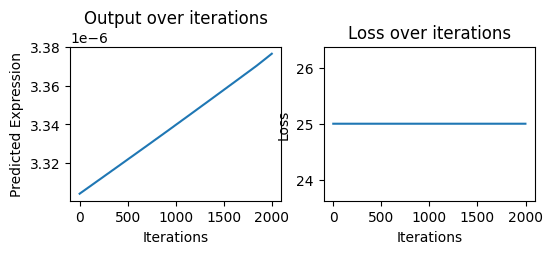

In [82]:
fig, axs = plt.subplots(1, 2, figsize=(6, 2))

#axs[0].plot(np.squeeze(outputs_zero))
axs[0].plot(np.squeeze(outputs_ten))
axs[0].set_title('Output over iterations')
axs[0].set_xlabel('Iterations')
axs[0].set_ylabel('Predicted Expression')

#axs[1].plot(np.squeeze(losses_zero))
axs[1].plot(np.squeeze(losses_ten))
axs[1].set_title('Loss over iterations')
axs[1].set_xlabel('Iterations')
axs[1].set_ylabel('Loss')

print(best_model.predict(input_data_single))
#print(best_model.predict(updated_zero_image))
print(best_model.predict(updated_ten_image))

Vsualization the differences in input image itself

<Figure size 640x480 with 0 Axes>

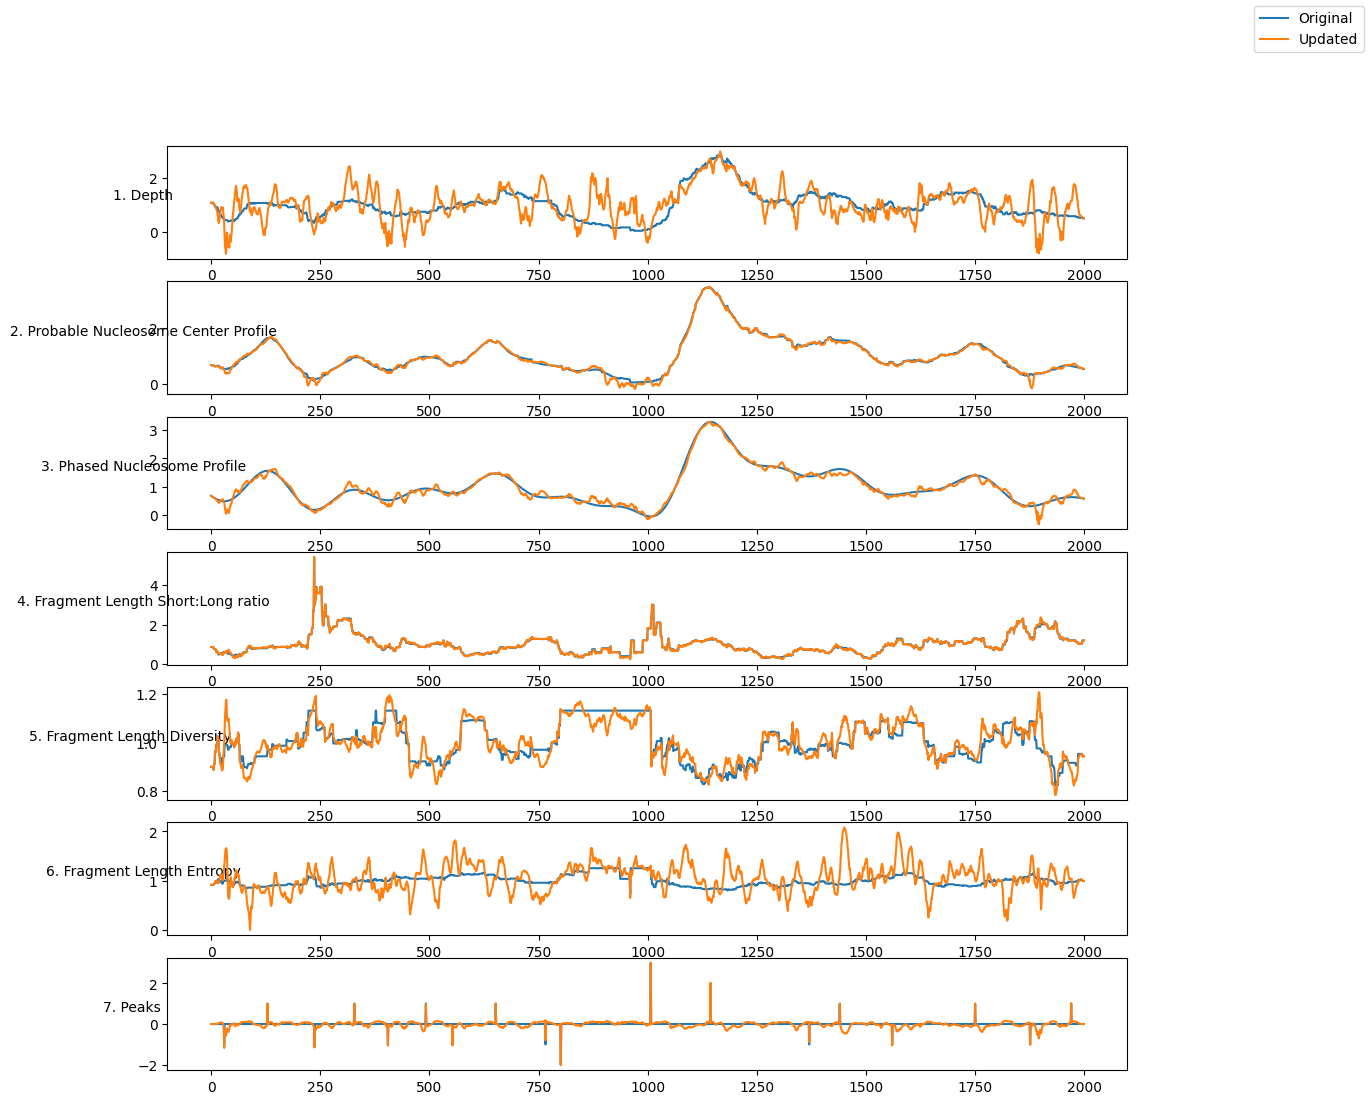

In [45]:
#Plot the input image
plt.clf()
cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks']
fig, axs = plt.subplots(len(cols), 1, figsize=(24, 12))
for i in range(len(cols)):
    axs[i].plot(input_data_single[0][0][:, i])
    axs[i].set_ylabel(cols[i], rotation=0)
    axs[i].plot(updated_ten_image[0][0][:, i])
    #axs[i, 1].set_ylabel(cols[i], rotation=0)

plt.subplots_adjust(left=0.5)
fig.legend(['Original', 'Updated'], loc='upper right')
plt.show()

invalid value encountered in divide


ValueError: alpha (nan) is outside 0-1 range

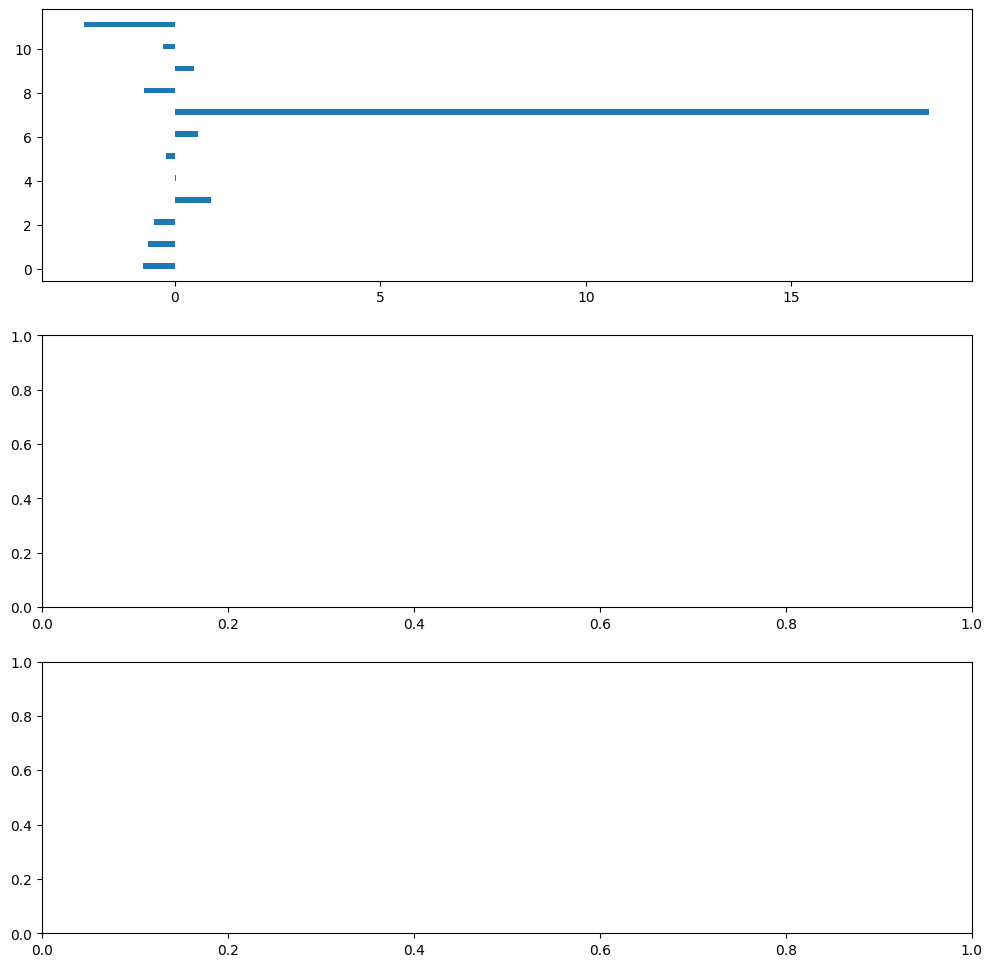

In [9]:
# Plot difference in value


TSS_scalar_cols = ['1. fragment-diversity', '2. fragment-entropy', '3. fragment-mad', '4. fragment-mean', '5. fragment-median', '6. fragment-ratio', '7. fragment-stdev', '8. mean-depth', '9. np-amplitude', '10. np-period', '11. np-score', '12. var-ratio' ]
ref_scalar_cols = ['1. numexons', '2. transcript_length', '3. mRNA_size']
cols_list = [TSS_scalar_cols, TSS_scalar_cols, ref_scalar_cols]

bar_width = 0.5
fig, axs = plt.subplots(3,1, figsize=(12, 12))

rel_diff_prelim_list = []
for i in range(3):
    rel_diff = (np.abs(updated_ten_image[i+1][0] - input_data_single[i+1][0])) / np.abs(input_data_single[i+1][0])
    if i == 0:
        min_val = np.min(rel_diff)
        max_val = np.max(rel_diff)
    else:
        if np.min(rel_diff) < min_val:
            min_val = np.min(rel_diff)
        if np.max(rel_diff) > max_val:
            max_val = np.max(rel_diff)
    rel_diff_prelim_list.append(rel_diff)

rel_diff_list = []
for i in range(3):
    rel_diff_list.append((((rel_diff_prelim_list[i] - min_val) / (max_val - min_val))*(9/10) + 1/10).tolist())


title_list = ['TSS Scalars', 'GB Scalars', 'Ref Scalars']
for i in range(3):
    bars = axs[i].barh(np.arange(len(cols_list[i])) + bar_width/4, input_data_single[i+1][0], height=bar_width/2, label='Original')
    for bar, alpha in zip(bars, rel_diff_list[i]):
        bar.set_alpha(alpha)
    bars = axs[i].barh(np.arange(len(cols_list[i])) - bar_width/4, updated_ten_image[i+1][0], height=bar_width/2, label='Updated')
    for bar, alpha in zip(bars, rel_diff_list[i]):
        bar.set_alpha(alpha)
    axs[i].set_xlabel('Value')
    axs[i].set_yticks(np.arange(len(cols_list[i])), cols_list[i])
    axs[i].set_title(f'{title_list[i]} Pre and Post Gradient Ascent')


fig.legend(['Original', 'Updated'], loc='upper right')
fig.show()